In [111]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from utils.load_data import load_data

### Data Prep & Cleaning

In [112]:
df = load_data(full=False)
df.head(15)

Loading existing sample...


,FIRE_YEAR,DISCOVERY_DATE,DISCOVERY_DOY,DISCOVERY_TIME,LATITUDE,LONGITUDE,STATE,STAT_CAUSE_DESCR,FIRE_SIZE,FIRE_SIZE_CLASS
0,2013,2456557.5,265,0700,37.516010,-119.623040,CA,Lightning,0.10,A
1,2003,2452841.5,202,1045,33.050833,-108.452500,NM,Lightning,0.25,A
2,2006,2454052.5,317,NaN,32.172945,-81.464159,GA,Debris Burning,1.00,B
3,2008,2454726.5,261,1325,48.059640,-123.186530,WA,Miscellaneous,0.10,A
4,2003,2452917.5,278,NaN,32.241889,-83.045710,GA,Debris Burning,0.07,A
5,2002,2452384.5,110,NaN,32.618100,-81.014200,SC,Debris Burning,1.00,B
6,2009,2454912.5,81,1130,37.777370,-85.807380,KY,Campfire,1.00,B
7,2005,2453734.5,364,1400,35.635000,-88.578333,TN,Debris Burning,1.00,B
8,2013,2456485.5,193,2300,40.419809,-112.322011,UT,Campfire,0.10,A
9,1996,2450130.5,48,1544,31.490394,-89.543970,MS,Debris Burning,2.00,B


In [113]:
df.columns = df.columns.str.lower()
print(df.isnull().sum())

fire_year                0
discovery_date           0
discovery_doy            0
discovery_time      234695
latitude                 0
longitude                0
state                    0
stat_cause_descr         0
fire_size                0
fire_size_class          0
dtype: int64


In [114]:
## Cleaning and transforming some columns

SIZE_LABELS = {"A": "Tiny", "B": "Small", "C": "Medium", "D": "Large",
                 "E": "Very large", "F": "Major", "G": "Catastrophic"}
df["fire_size_label"] = pd.Categorical(
    df["fire_size_class"].map(SIZE_LABELS),
    categories=list(SIZE_LABELS.values()), ordered=True,
)

df['is_large'] = df["fire_size_class"].isin(list("CDEFG")).astype(int)

df["discovery_hour"] = pd.to_numeric(df["discovery_time"], errors="coerce") // 100
df = df.drop(columns="discovery_time")


d = pd.to_datetime(df["discovery_date"], unit="D", origin="julian")
df["month"] = d.dt.month
df["day_of_week"] = d.dt.day_of_week
df = df.drop(columns="discovery_date")

In [115]:
df.head()

,fire_year,discovery_doy,latitude,longitude,state,stat_cause_descr,fire_size,fire_size_class,fire_size_label,is_large,discovery_hour,month,day_of_week
0,2013,265,37.516010,-119.623040,CA,Lightning,0.10,A,Tiny,0,7.0,9,6
1,2003,202,33.050833,-108.452500,NM,Lightning,0.25,A,Tiny,0,10.0,7,0
2,2006,317,32.172945,-81.464159,GA,Debris Burning,1.00,B,Small,0,NaN,11,0
3,2008,261,48.059640,-123.186530,WA,Miscellaneous,0.10,A,Tiny,0,13.0,9,2
4,2003,278,32.241889,-83.045710,GA,Debris Burning,0.07,A,Tiny,0,NaN,10,6


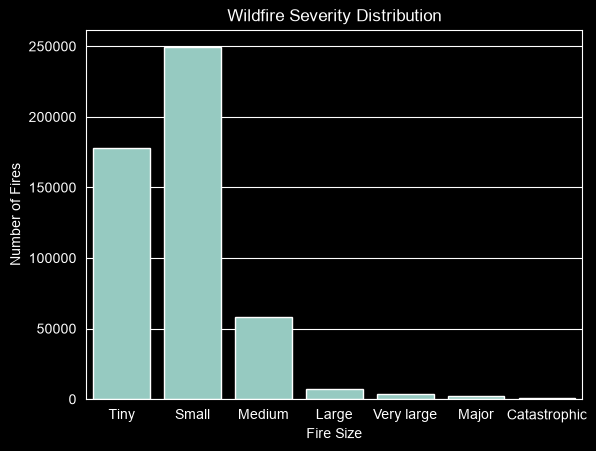

In [116]:
sns.countplot(
    data=df,
    x="fire_size_label",
    order=list(SIZE_LABELS.values()),
)

plt.title("Wildfire Severity Distribution")
plt.xlabel("Fire Size")
plt.ylabel("Number of Fires")
plt.show()

In [117]:
distribution_by_year = pd.crosstab(
    df["fire_year"],
    df["fire_size_label"],
    normalize="index",
) * 100

display(distribution_by_year.round(2))

fire_size_label,Tiny,Small,Medium,Large,Very large,Major,Catastrophic
fire_year,,,,,,,
1992,37.84,48.44,11.74,1.17,0.47,0.26,0.08
1993,33.53,52.25,11.91,1.31,0.65,0.26,0.09
1994,36.62,48.87,11.39,1.55,0.87,0.53,0.17
1995,33.56,51.53,12.43,1.44,0.68,0.31,0.05
1996,33.08,50.27,13.34,1.56,1.03,0.45,0.28
1997,35.61,51.85,10.72,1.13,0.40,0.19,0.12
1998,34.52,51.63,11.49,1.38,0.64,0.24,0.10
1999,31.08,53.27,12.86,1.48,0.72,0.41,0.18
2000,33.85,50.13,12.63,1.71,0.89,0.53,0.25


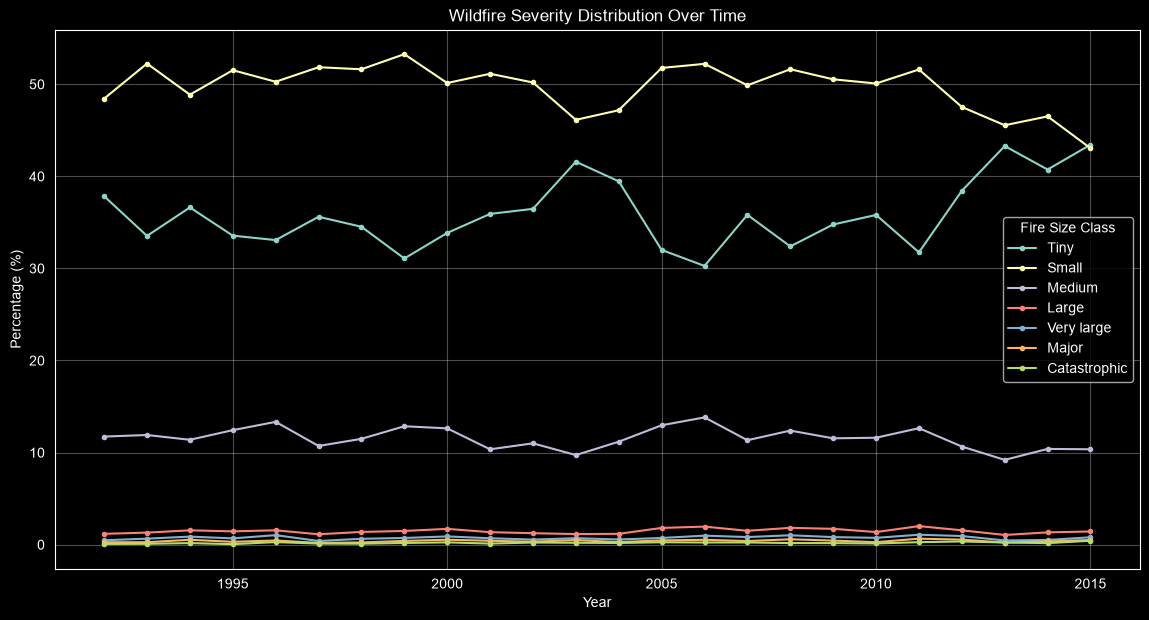

In [118]:
distribution_by_year.plot(
    figsize=(14, 7),
    kind="line",
    marker=".",
)

plt.title("Wildfire Severity Distribution Over Time")
plt.xlabel("Year")
plt.ylabel("Percentage (%)")
plt.legend(title="Fire Size Class")
plt.grid(alpha=0.3)
plt.show()

In [119]:
df.columns

Index(['fire_year', 'discovery_doy', 'latitude', 'longitude', 'state',
       'stat_cause_descr', 'fire_size', 'fire_size_class', 'fire_size_label',
       'is_large', 'discovery_hour', 'month', 'day_of_week'],
      dtype='str')

### Target / feature split and train-validation-test split

In [120]:
from sklearn.model_selection import train_test_split

TARGET = "is_large"
LEAKY = ["fire_size_class","fire_size", "fire_size_label"]

y = df[TARGET]
X = df.drop(columns=[TARGET, *LEAKY])

# 60% train / 20% validation / 20% test, stratified so rare classes appear in every split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)

print("\nClass distribution (%) per split:")
print(
    pd.DataFrame({
        "train": y_train.value_counts(normalize=True),
        "val": y_val.value_counts(normalize=True),
        "test": y_test.value_counts(normalize=True),
    }).mul(100).round(2).sort_index()
)



Class distribution (%) per split:
          train    val   test
is_large                     
0         85.45  85.45  85.45
1         14.55  14.55  14.55


### EDA (training set only)

Exploring only `X_train` so nothing from the validation/test sets influences our decisions. "Large" below means classes C-G (10+ acres).

In [121]:
train = X_train.assign(is_large=y_train)

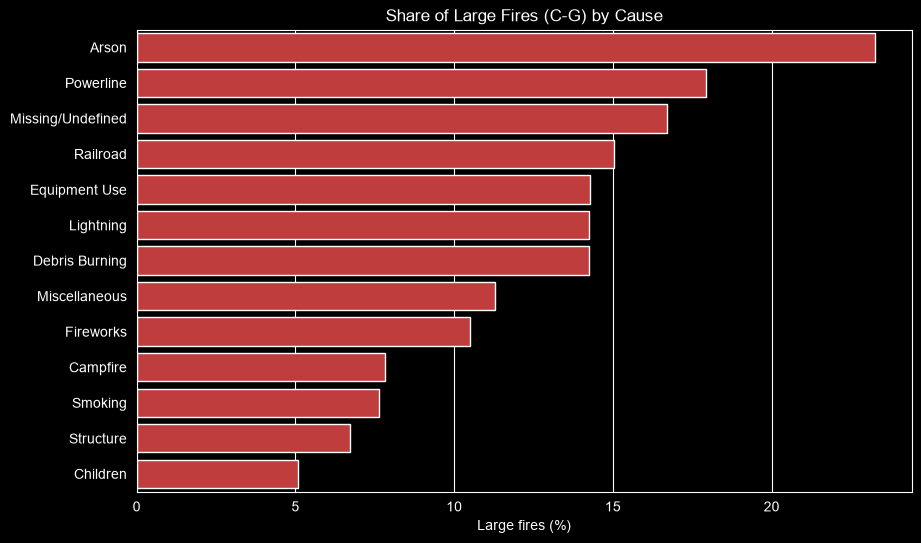

In [122]:
# Share of large fires by cause
large_by_cause = (
    train.groupby("stat_cause_descr")["is_large"].mean().mul(100).sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=large_by_cause.values, y=large_by_cause.index, color="tab:red")
plt.title("Share of Large Fires (C-G) by Cause")
plt.xlabel("Large fires (%)")
plt.ylabel("")
plt.show()

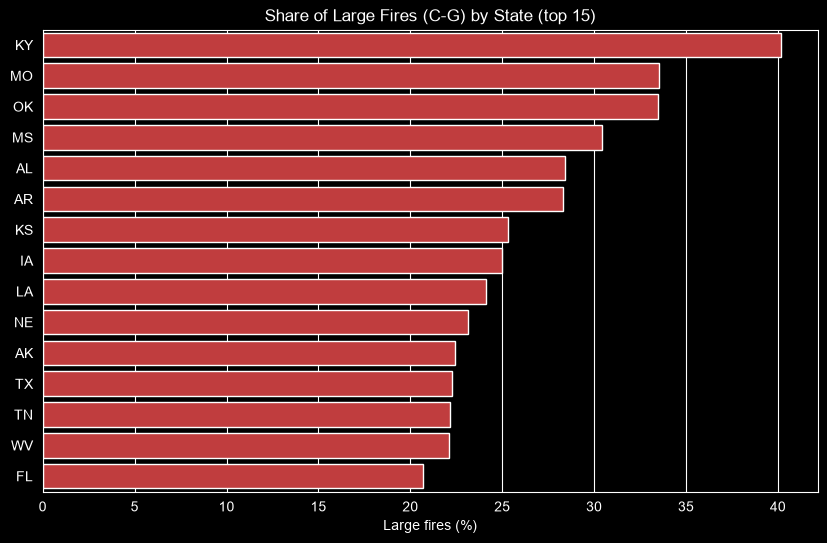

In [123]:
# Share of large fires by state (states with at least 500 fires, top 15)
by_state = train.groupby("state")["is_large"].agg(["mean", "size"])
by_state = by_state[by_state["size"] >= 500]["mean"].mul(100).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=by_state.values, y=by_state.index, color="tab:red")
plt.title("Share of Large Fires (C-G) by State (top 15)")
plt.xlabel("Large fires (%)")
plt.ylabel("")
plt.show()

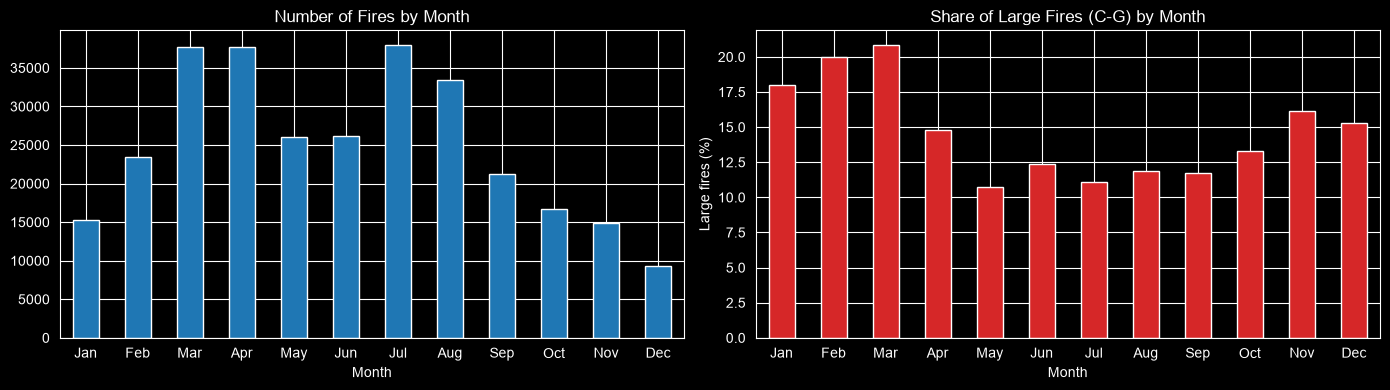

In [124]:
# Seasonality: how many fires, and how many of them are large, per month
import calendar

month_labels = list(calendar.month_abbr)[1:]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

train["month"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color="tab:blue"
)
axes[0].set_title("Number of Fires by Month")
axes[0].set_xlabel("Month")

train.groupby("month")["is_large"].mean().mul(100).plot(
    kind="bar", ax=axes[1], color="tab:red"
)
axes[1].set_title("Share of Large Fires (C-G) by Month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Large fires (%)")

for ax in axes:
    ax.set_xticklabels(month_labels, rotation=0)

plt.tight_layout()
plt.show()

In [125]:
X_train.head()

,fire_year,discovery_doy,latitude,longitude,state,stat_cause_descr,discovery_hour,month,day_of_week
29715,1998,117,47.073768,-95.308036,MN,Arson,NaN,4,0
13917,1999,71,34.016700,-79.666700,SC,Debris Burning,NaN,3,4
495744,2010,136,46.214528,-67.792611,ME,Miscellaneous,NaN,5,6
400724,2014,114,40.722300,-73.579600,NY,Arson,19.0,4,3
64813,2004,15,34.133890,-82.415830,SC,Equipment Use,NaN,1,3


### Modelling setup

The target is `is_large` (class C-G, 10+ acres), about 15% of all fires. Accuracy is misleading here (always predicting "small" already scores ~85%), so every model is scored on the validation set with five numbers:

* **roc_auc**: how well the model ranks large fires above small ones. It does not depend on a threshold, so it is the number used to compare models and hyperparameters.
* **threshold**: the probability cut-off that gives the best F1 for the Large class.
* **precision / recall / f1**: for the Large class, at that threshold.

Two helpers do all the work: `evaluate(name, model)` adds a fitted model to the results table, and `tune(...)` fits one model per hyperparameter value and plots train vs validation ROC-AUC.

In [126]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

categorical = ["state", "stat_cause_descr"]
numeric = [c for c in X_train.columns if c not in categorical]

# Linear model: fill the missing discovery_hour (and flag it), scale the numbers, one-hot the categories
linear_preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])

# Tree models: categories become integer codes, numbers pass through untouched (trees handle NaN themselves)
tree_preprocess = ColumnTransformer(
    [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical)],
    remainder="passthrough",
)

results = {}   # model name -> validation metrics


def best_f1(y_true, proba):
    """Threshold with the best F1 for the Large class, and precision / recall / F1 at that threshold."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    i = f1[:-1].argmax()
    return {"threshold": thresholds[i], "precision": precision[i], "recall": recall[i], "f1": f1[i]}


def evaluate(name, model):
    """Score a fitted model on the validation set and add it to the results table."""
    proba = model.predict_proba(X_val)[:, 1]
    results[name] = {"roc_auc": roc_auc_score(y_val, proba), **best_f1(y_val, proba)}
    return pd.DataFrame(results).T.round(3)


def tune(title, param, values, make_model):
    """Fit one model per value of a hyperparameter; table + plot of train vs validation ROC-AUC."""
    rows = []
    for value in values:
        model = make_model(value).fit(X_train, y_train)
        val_proba = model.predict_proba(X_val)[:, 1]
        rows.append({
            param: str(value),
            "train_auc": roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]),
            "val_auc": roc_auc_score(y_val, val_proba),
            "val_f1": best_f1(y_val, val_proba)["f1"],
        })
    table = pd.DataFrame(rows).set_index(param)

    ax = table[["train_auc", "val_auc"]].plot(marker="o", figsize=(7, 3.5))
    ax.set_xticks(range(len(table)), table.index)
    ax.set_title(f"{title}: ROC-AUC vs {param}")
    ax.set_ylabel("ROC-AUC")
    ax.grid(alpha=0.3)
    plt.show()
    return table.round(4)

### Baseline

Always predicting the share of large fires: ROC-AUC 0.5, and the best possible F1 comes from flagging every fire as large. Every real model has to beat this.

In [127]:
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
evaluate("baseline", dummy)

,roc_auc,threshold,precision,recall,f1
baseline,0.5,0.145,0.146,1.0,0.254


### Logistic regression

One hyperparameter matters: `C` (inverse regularisation strength).

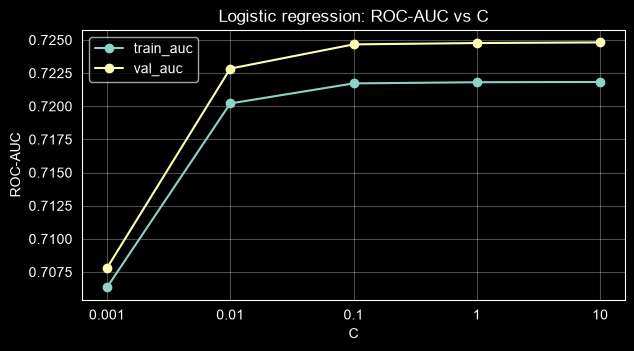

,train_auc,val_auc,val_f1
C,,,
0.001,0.7063,0.7078,0.3585
0.01,0.7202,0.7228,0.3748
0.1,0.7217,0.7247,0.3752
1,0.7218,0.7248,0.3746
10,0.7218,0.7248,0.3745


In [128]:
tune(
    "Logistic regression", "C", [0.001, 0.01, 0.1, 1, 10],
    lambda C: make_pipeline(linear_preprocess, LogisticRegression(C=C, max_iter=1000)),
)

From `C=0.01` upwards the score does not move (only very strong regularisation, `C=0.001`, hurts a little), and train and validation scores are identical: the model is underfitting, not overfitting. A linear model cannot express "this region, in this season", so it is limited by its shape, not by regularisation. Keeping the default `C=1`.

In [129]:
logreg = make_pipeline(linear_preprocess, LogisticRegression(C=1, max_iter=1000)).fit(X_train, y_train)
evaluate("logistic regression", logreg)

,roc_auc,threshold,precision,recall,f1
baseline,0.500,0.145,0.146,1.000,0.254
logistic regression,0.725,0.185,0.276,0.582,0.375


### Decision tree

`max_depth` controls how complex the tree may get, `min_samples_leaf` how few fires a leaf may hold.

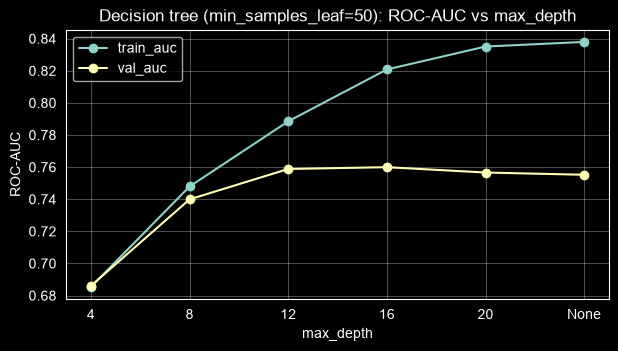

,train_auc,val_auc,val_f1
max_depth,,,
4,0.6854,0.6861,0.3514
8,0.7479,0.7399,0.3873
12,0.7885,0.7588,0.4098
16,0.8208,0.7599,0.4161
20,0.8351,0.7566,0.4151
None,0.8380,0.7552,0.4137


In [130]:
tune(
    "Decision tree (min_samples_leaf=50)", "max_depth", [4, 8, 12, 16, 20, None],
    lambda d: make_pipeline(tree_preprocess, DecisionTreeClassifier(max_depth=d, min_samples_leaf=50, random_state=42)),
)

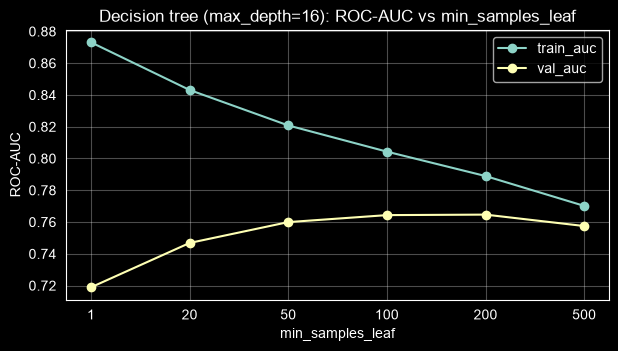

,train_auc,val_auc,val_f1
min_samples_leaf,,,
1,0.8731,0.7189,0.3995
20,0.8431,0.7468,0.4040
50,0.8208,0.7599,0.4161
100,0.8043,0.7643,0.4162
200,0.7889,0.7647,0.4149
500,0.7702,0.7575,0.4081


In [131]:
tune(
    "Decision tree (max_depth=16)", "min_samples_leaf", [1, 20, 50, 100, 200, 500],
    lambda n: make_pipeline(tree_preprocess, DecisionTreeClassifier(max_depth=16, min_samples_leaf=n, random_state=42)),
)

Deeper trees keep improving on the training set, but validation ROC-AUC flattens around depth 12-16: past that the tree is memorising. Tiny leaves (`min_samples_leaf=1`) overfit badly; 100-200 is the sweet spot. Using `max_depth=16, min_samples_leaf=100`.

In [132]:
tree = make_pipeline(
    tree_preprocess, DecisionTreeClassifier(max_depth=16, min_samples_leaf=100, random_state=42)
).fit(X_train, y_train)
evaluate("decision tree", tree)

,roc_auc,threshold,precision,recall,f1
baseline,0.500,0.145,0.146,1.000,0.254
logistic regression,0.725,0.185,0.276,0.582,0.375
decision tree,0.764,0.206,0.324,0.582,0.416


### Random forest

`n_estimators` is the number of trees, `min_samples_leaf` again limits how specific each tree gets.

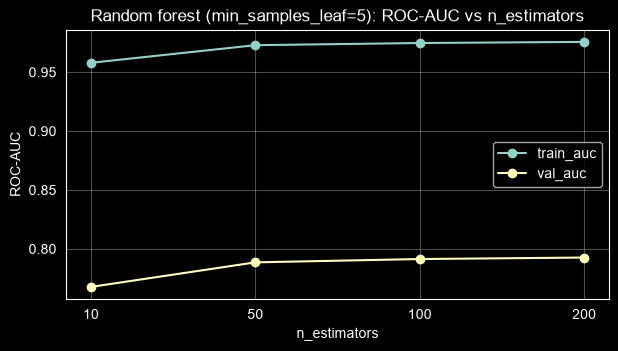

,train_auc,val_auc,val_f1
n_estimators,,,
10,0.9580,0.7677,0.4225
50,0.9729,0.7885,0.4412
100,0.9748,0.7914,0.4442
200,0.9757,0.7926,0.4449


In [133]:
tune(
    "Random forest (min_samples_leaf=5)", "n_estimators", [10, 50, 100, 200],
    lambda n: make_pipeline(tree_preprocess, RandomForestClassifier(n_estimators=n, min_samples_leaf=5, n_jobs=-1, random_state=42)),
)

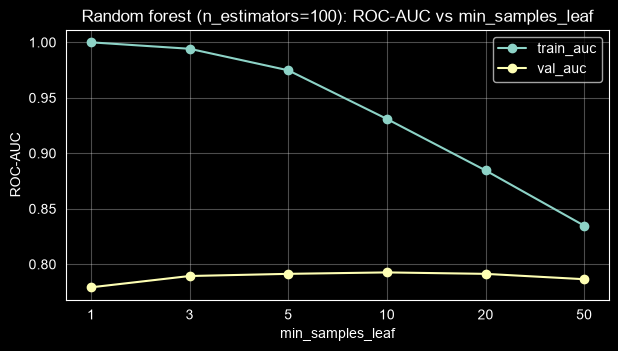

,train_auc,val_auc,val_f1
min_samples_leaf,,,
1,1.0000,0.7792,0.4305
3,0.9942,0.7894,0.4430
5,0.9748,0.7914,0.4442
10,0.9309,0.7926,0.4445
20,0.8846,0.7913,0.4417
50,0.8348,0.7865,0.4350


In [134]:
tune(
    "Random forest (n_estimators=100)", "min_samples_leaf", [1, 3, 5, 10, 20, 50],
    lambda n: make_pipeline(tree_preprocess, RandomForestClassifier(n_estimators=100, min_samples_leaf=n, n_jobs=-1, random_state=42)),
)

More trees help until about 100, then the gain is tiny. The forest scores far higher on train than on validation (individual trees memorise), but averaging keeps validation stable; `min_samples_leaf=10` is the best trade-off. Using `n_estimators=200, min_samples_leaf=10`.

In [135]:
rf = make_pipeline(
    tree_preprocess, RandomForestClassifier(n_estimators=200, min_samples_leaf=10, n_jobs=-1, random_state=42)
).fit(X_train, y_train)
evaluate("random forest", rf)

,roc_auc,threshold,precision,recall,f1
baseline,0.500,0.145,0.146,1.000,0.254
logistic regression,0.725,0.185,0.276,0.582,0.375
decision tree,0.764,0.206,0.324,0.582,0.416
random forest,0.794,0.219,0.359,0.589,0.446


### XGBoost

Tuned one parameter at a time: `learning_rate`, then `max_depth`, then `min_child_weight`.

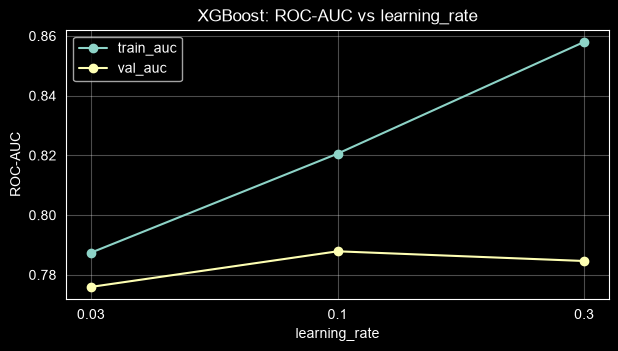

,train_auc,val_auc,val_f1
learning_rate,,,
0.03,0.7874,0.7760,0.4290
0.1,0.8206,0.7879,0.4398
0.3,0.8580,0.7846,0.4363


In [136]:
def make_xgb(**params):
    defaults = dict(
        n_estimators=300, learning_rate=0.1, max_depth=6, subsample=0.8, colsample_bytree=0.8,
        tree_method="hist", n_jobs=-1, random_state=42,
    )
    return make_pipeline(tree_preprocess, XGBClassifier(**{**defaults, **params}))


tune("XGBoost", "learning_rate", [0.03, 0.1, 0.3], lambda lr: make_xgb(learning_rate=lr))

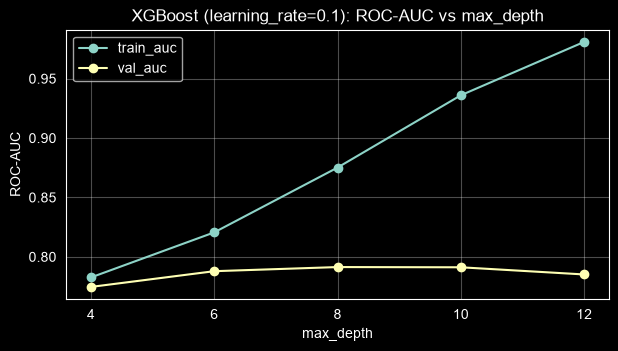

,train_auc,val_auc,val_f1
max_depth,,,
4,0.7826,0.7746,0.4278
6,0.8206,0.7879,0.4398
8,0.8751,0.7913,0.4438
10,0.9360,0.7912,0.4439
12,0.9809,0.7851,0.4362


In [137]:
tune("XGBoost (learning_rate=0.1)", "max_depth", [4, 6, 8, 10, 12], lambda d: make_xgb(max_depth=d))

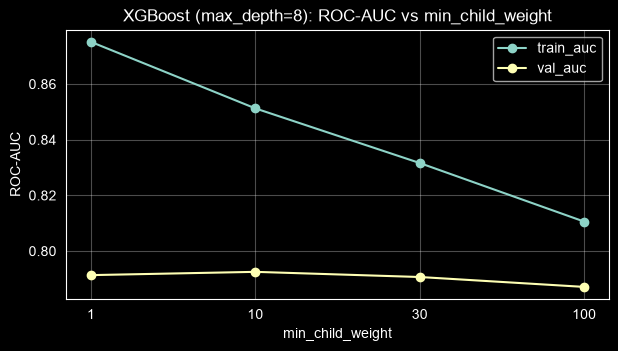

,train_auc,val_auc,val_f1
min_child_weight,,,
1,0.8751,0.7913,0.4438
10,0.8512,0.7925,0.4446
30,0.8316,0.7907,0.4407
100,0.8106,0.7871,0.4397


In [138]:
tune("XGBoost (max_depth=8)", "min_child_weight", [1, 10, 30, 100], lambda w: make_xgb(max_depth=8, min_child_weight=w))

`learning_rate=0.1` is best for 300 trees. Validation ROC-AUC peaks at `max_depth=8`; deeper trees only raise the training score. `min_child_weight=10` closes part of the train/validation gap without hurting validation. Using `learning_rate=0.1, max_depth=8, min_child_weight=10`.

In [139]:
xgb = make_xgb(max_depth=8, min_child_weight=10).fit(X_train, y_train)
evaluate("xgboost", xgb)

,roc_auc,threshold,precision,recall,f1
baseline,0.500,0.145,0.146,1.000,0.254
logistic regression,0.725,0.185,0.276,0.582,0.375
decision tree,0.764,0.206,0.324,0.582,0.416
random forest,0.794,0.219,0.359,0.589,0.446
xgboost,0.793,0.223,0.366,0.565,0.445


### Class imbalance

Only ~15% of fires are large. The usual fix is to give the Large class more weight during training (`class_weight="balanced"`, or `scale_pos_weight` in XGBoost). Each model is trained here with and without weights, and scored both at the default 0.5 threshold and at its best-F1 threshold.

In [140]:
NEG_POS = (y_train == 0).sum() / (y_train == 1).sum()   # ~5.9 small fires per large fire

candidates = {
    "logistic regression": logreg,
    "logistic regression (weighted)": make_pipeline(
        linear_preprocess, LogisticRegression(C=1, class_weight="balanced", max_iter=1000)),
    "random forest": rf,
    "random forest (weighted)": make_pipeline(
        tree_preprocess, RandomForestClassifier(
            n_estimators=200, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=-1, random_state=42)),
    "xgboost": xgb,
    "xgboost (weighted)": make_xgb(max_depth=8, min_child_weight=10, scale_pos_weight=NEG_POS),
}

rows = {}
for name, model in candidates.items():
    if "weighted" in name:
        model.fit(X_train, y_train)
    proba = model.predict_proba(X_val)[:, 1]
    best = best_f1(y_val, proba)
    rows[name] = {
        "roc_auc": roc_auc_score(y_val, proba),
        "f1 at 0.5": f1_score(y_val, proba >= 0.5),
        "best threshold": best["threshold"],
        "f1 at best threshold": best["f1"],
    }

pd.DataFrame(rows).T.round(3)

,roc_auc,f1 at 0.5,best threshold,f1 at best threshold
logistic regression,0.725,0.014,0.185,0.375
logistic regression (weighted),0.725,0.365,0.567,0.374
random forest,0.794,0.171,0.219,0.446
random forest (weighted),0.793,0.444,0.464,0.445
xgboost,0.793,0.205,0.223,0.445
xgboost (weighted),0.791,0.432,0.581,0.440


Weighting does not make the models better: ROC-AUC and the best achievable F1 are the same with or without it (marginally lower for XGBoost). What changes is where the probabilities sit. Unweighted models rarely output more than 0.5 for a fire, so F1 at 0.5 looks terrible, while weighted models are pushed towards 0.5. Choosing the threshold on the validation set achieves the same thing as weighting, and keeps the predicted probabilities closer to the real share of large fires instead of inflating them. So the models stay unweighted and the imbalance is handled with the threshold.

### Comparison

,roc_auc,threshold,precision,recall,f1
baseline,0.500,0.145,0.146,1.000,0.254
logistic regression,0.725,0.185,0.276,0.582,0.375
decision tree,0.764,0.206,0.324,0.582,0.416
random forest,0.794,0.219,0.359,0.589,0.446
xgboost,0.793,0.223,0.366,0.565,0.445


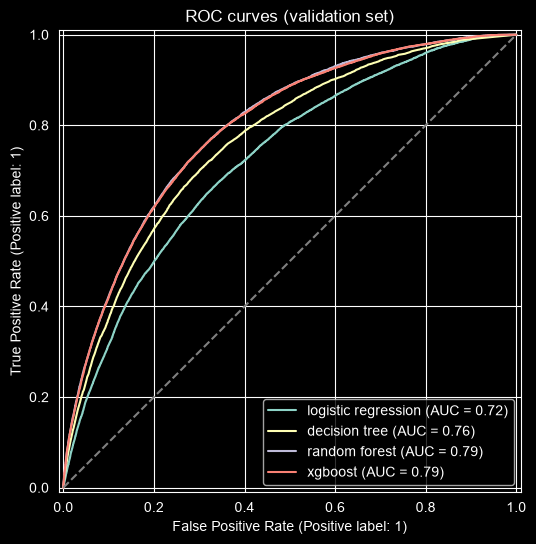

In [141]:
comparison = pd.DataFrame(results).T.round(3)
display(comparison)

fig, ax = plt.subplots(figsize=(6, 6))
for name, model in {"logistic regression": logreg, "decision tree": tree, "random forest": rf, "xgboost": xgb}.items():
    RocCurveDisplay.from_estimator(model, X_val, y_val, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey")
ax.set_title("ROC curves (validation set)")
plt.show()

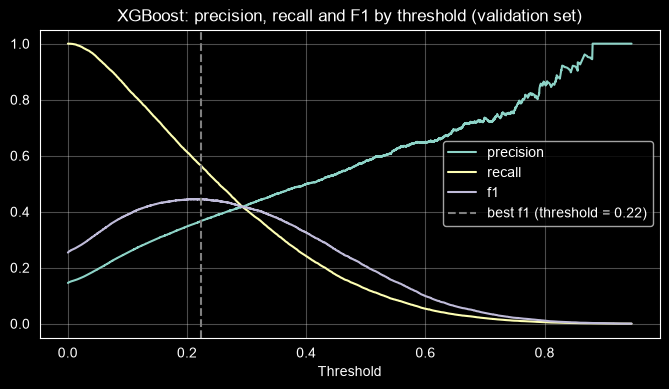

In [142]:
# How the threshold trades precision for recall, for the final model
val_proba = xgb.predict_proba(X_val)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, val_proba)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
THRESHOLD = best_f1(y_val, val_proba)["threshold"]

plt.figure(figsize=(8, 4))
plt.plot(thresholds, precision[:-1], label="precision")
plt.plot(thresholds, recall[:-1], label="recall")
plt.plot(thresholds, f1[:-1], label="f1")
plt.axvline(THRESHOLD, linestyle="--", color="grey", label=f"best f1 (threshold = {THRESHOLD:.2f})")
plt.title("XGBoost: precision, recall and F1 by threshold (validation set)")
plt.xlabel("Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Random forest and XGBoost are level, clearly ahead of the single tree and logistic regression. XGBoost is the final model: same score, but it trains faster and is a much smaller model to save and deploy. Lowering the threshold catches more large fires at the cost of more false alarms; the dashed line is the F1-optimal point.

### Final model on the test set

The test set has not been used so far. The threshold is the one chosen on the validation set.

roc_auc      0.791
threshold    0.223
precision    0.361
recall       0.555
f1           0.438


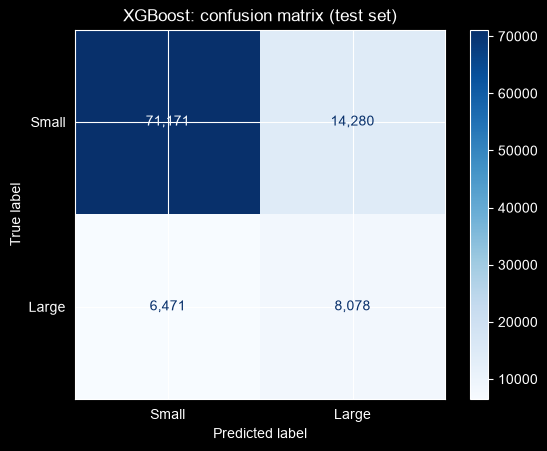

In [143]:
test_proba = xgb.predict_proba(X_test)[:, 1]
test_pred = test_proba >= THRESHOLD

print(pd.Series({
    "roc_auc": roc_auc_score(y_test, test_proba),
    "threshold": THRESHOLD,
    "precision": precision_score(y_test, test_pred),
    "recall": recall_score(y_test, test_pred),
    "f1": f1_score(y_test, test_pred),
}).round(3).to_string())

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Small", "Large"], cmap="Blues", values_format=",",
)
plt.title("XGBoost: confusion matrix (test set)")
plt.show()

### Full dataset

Everything above used a 500,000-row sample, which keeps the hyperparameter sweeps fast. Here the final XGBoost, with the same hyperparameters, is trained on all ~1.88 million fires to see how much more data helps.

Same cleaning, same 60/20/20 split, threshold again chosen on the validation set. Each model is scored on its own test set (20% of the data it was built from), because the sample's rows are also part of the full dataset.

In [144]:
from sklearn.base import clone

df_full = load_data(full=True)
df_full.columns = df_full.columns.str.lower()

# Same cleaning as for the sample
df_full["is_large"] = df_full["fire_size_class"].isin(list("CDEFG")).astype(int)
df_full["discovery_hour"] = pd.to_numeric(df_full["discovery_time"], errors="coerce") // 100
d_full = pd.to_datetime(df_full["discovery_date"], unit="D", origin="julian")
df_full["month"] = d_full.dt.month
df_full["day_of_week"] = d_full.dt.day_of_week

y_full = df_full["is_large"]
X_full = df_full[X_train.columns]   # exactly the features the sample model uses

# Same 60% train / 20% validation / 20% test split
X_train_full, X_temp_full, y_train_full, y_temp_full = train_test_split(
    X_full, y_full, test_size=0.4, stratify=y_full, random_state=42
)
X_val_full, X_test_full, y_val_full, y_test_full = train_test_split(
    X_temp_full, y_temp_full, test_size=0.5, stratify=y_temp_full, random_state=42
)

print(f"train: {len(X_train_full):,}   validation: {len(X_val_full):,}   test: {len(X_test_full):,}")
print(f"Share of large fires: {y_train_full.mean():.2%}")

Loading existing full dataset...
train: 1,128,279   validation: 376,093   test: 376,093
Share of large fires: 14.58%


In [145]:
# Final model, same hyperparameters. clone() gives it its own preprocessing, so the sample model is left untouched.
xgb_full = make_pipeline(
    clone(tree_preprocess),
    XGBClassifier(
        n_estimators=300, learning_rate=0.1, max_depth=8, min_child_weight=10,
        subsample=0.8, colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=42,
    ),
).fit(X_train_full, y_train_full)

# Threshold chosen on the validation set, then used as is on the test set
THRESHOLD_FULL = best_f1(y_val_full, xgb_full.predict_proba(X_val_full)[:, 1])["threshold"]
test_proba_full = xgb_full.predict_proba(X_test_full)[:, 1]
test_pred_full = test_proba_full >= THRESHOLD_FULL

In [146]:
def test_scores(train_rows, y_true, proba, threshold):
    pred = proba >= threshold
    return {
        "train rows": f"{train_rows:,}",
        "roc_auc": round(roc_auc_score(y_true, proba), 3),
        "threshold": round(threshold, 3),
        "precision": round(precision_score(y_true, pred), 3),
        "recall": round(recall_score(y_true, pred), 3),
        "f1": round(f1_score(y_true, pred), 3),
    }


pd.DataFrame({
    "sample": test_scores(len(X_train), y_test, test_proba, THRESHOLD),
    "full": test_scores(len(X_train_full), y_test_full, test_proba_full, THRESHOLD_FULL),
})

,sample,full
train rows,"300,000","1,128,279"
roc_auc,0.791,0.803
threshold,0.223,0.228
precision,0.361,0.379
recall,0.555,0.571
f1,0.438,0.456


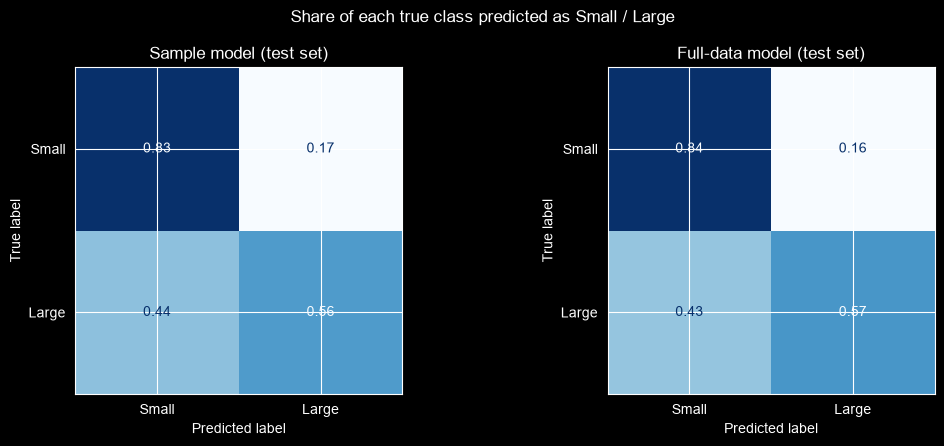

In [147]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, normalize="true", values_format=".2f", cmap="Blues",
    display_labels=["Small", "Large"], ax=axes[0], colorbar=False,
)
axes[0].set_title("Sample model (test set)")
ConfusionMatrixDisplay.from_predictions(
    y_test_full, test_pred_full, normalize="true", values_format=".2f", cmap="Blues",
    display_labels=["Small", "Large"], ax=axes[1], colorbar=False,
)
axes[1].set_title("Full-data model (test set)")
plt.suptitle("Share of each true class predicted as Small / Large")
plt.tight_layout()
plt.show()

### What does all of this tell us?

**The question.** A fire has just been discovered. We know when it started, where it is and what caused it. Can we tell whether it will grow into a large fire (10 acres or more)?

**The short answer.** Partly. The model is clearly better than guessing, but it is far from a crystal ball.

**Why we did not use accuracy.** Only about 15 out of every 100 fires become large. A "model" that says *small* every single time would be right 85% of the time and would never catch a single large fire. So a high accuracy means nothing here. Instead we asked two questions: of the fires we flag as large, how many really are (**precision**)? And of the fires that really are large, how many did we flag (**recall**)? **F1** is one number that combines the two.

**What the final model does, in plain numbers.** Imagine 100 new fires. About 15 of them will become large, but the model does not know which ones. It gives every fire a risk score and raises a flag on the fires that score above the threshold: about 22 of the 100. The flagged fires and the truly large fires are two different groups that only partly overlap:

| | Flagged by the model | Not flagged | Total |
|---|---|---|---|
| **Really large** | 8 (caught) | 6 to 7 (missed) | about 15 |
| **Really small** | 14 (false alarms) | about 71 | about 85 |
| **Total** | about 22 | about 78 | 100 |

* **Recall** looks at the first row: of the 15 large fires, the model caught 8 (about 55%).
* **Precision** looks at the first column: of the 22 flags, 8 were right (about 36%).

Flagging fires at random would be right about 15% of the time; the model's flags are right about 36% of the time. That is roughly two and a half times better than chance, but it still means more false alarms than hits, and it still misses nearly half of the large fires.

**What ROC-AUC 0.79 means.** Take one fire that became large and one that stayed small. The model gives the higher risk score to the large one about 79 times out of 100. A coin flip would manage 50, a perfect model 100. So the model is best thought of as a way to *rank* fires by risk ("look at these first"), not as a yes/no answer to trust blindly.

**About the threshold.** The model does not say "large" or "small". It gives a probability, for example 0.30. We have to pick the point from which we call a fire large. Because large fires are rare, the model almost never goes above 0.5, so the usual cut-off of 0.5 would flag almost nothing. The cut-off that gave the best balance was about 0.22. This is a choice, not a law: lower it and we catch more large fires but raise more false alarms; raise it and the opposite happens. For wildfires, missing a large fire is probably worse than a false alarm, so in real use a lower threshold could make sense.

**What we learned from comparing the models.**

* Logistic regression was the weakest (ROC-AUC 0.725). It can only draw straight-line relationships, and "this area, in this season" is not a straight line.
* A single decision tree did better (0.764), and a team of many trees, random forest or XGBoost, did best (about 0.79).
* Random forest and XGBoost ended with almost the same score. When two very different methods hit the same ceiling, the ceiling is in the data, not in the method.
* Changing the hyperparameters moved the scores only a little. The plots show the typical pattern: a more complex model keeps getting better on the training data, but stops getting better on new data. That gap is overfitting, the model memorising instead of learning.
* Giving the rare class more weight did not make the models smarter. It only shifted the probabilities upwards. Picking a good threshold does the same job in a simpler way.

**Why the model cannot do much better.** How big a fire gets depends mostly on wind, heat, how dry the land is, what is growing there, and how fast firefighters arrive. None of that is in our table. We only know the date, the place and the cause, so the model can learn things like "fires in this region in this month tend to grow", and not much more.

**What would improve it.**

* More examples: the score was still rising as the training data grew, which is what the full-dataset section above checks.
* More information about each fire: weather and drought on the day of discovery would likely help the most.

**Bottom line.** With only when, where and why, we can sort fires into higher and lower risk reasonably well, and that is useful for deciding where to look first. We cannot reliably predict which individual fire will become large, and no amount of model tuning will change that without better data.